<a href="https://colab.research.google.com/github/zaaz-png/fds-EV_DATASET_ANALYSIS/blob/main/EV_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Washington EV Population - FDS Mini Competition
Simple version using only pandas, numpy and matplotlib.


In [1]:
import pandas as pd

In [2]:
from google.colab import files
files.upload()
df = pd.read_csv("export.csv")

Saving export.csv to export.csv


In [3]:
import numpy as np
import matplotlib.pyplot as plt

print("Shape:", df.shape)
print(df.head())
print(df.dtypes)

Shape: (300142, 16)
   VIN (1-10)    County        City State  Postal Code  Model Year   Make  \
0  3FMTK3SU8P      King     Seattle    WA      98177.0        2023   FORD   
1  JM3KKEHA8S  Thurston        Yelm    WA      98597.0        2025  MAZDA   
2  5YJ3E1EB8J      King   Sammamish    WA      98075.0        2018  TESLA   
3  JHMZC5F12K    Island  Oak Harbor    WA      98277.0        2019  HONDA   
4  1C4RJXN65R    Kitsap   Bremerton    WA      98312.0        2024   JEEP   

            Model                   Electric Vehicle Type  \
0  MUSTANG MACH-E          Battery Electric Vehicle (BEV)   
1           CX-90  Plug-in Hybrid Electric Vehicle (PHEV)   
2         MODEL 3          Battery Electric Vehicle (BEV)   
3         CLARITY  Plug-in Hybrid Electric Vehicle (PHEV)   
4        WRANGLER  Plug-in Hybrid Electric Vehicle (PHEV)   

   Clean Alternative Fuel Vehicle (CAFV) Eligibility  Electric Range  \
0  Eligibility unknown as battery range has not b...             0.0   
1     

## Phase 1: Dataset Understanding & Preprocessing
### 1.1 Attribute Identification
| Attribute | Type |
|---|---|
| VIN, County, City, State, Postal Code, Make, Model, Legislative District, DOL Vehicle ID, Electric Utility, 2020 GEOID | Nominal, Discrete |
| Electric Vehicle Type | Nominal (binary) |
| CAFV Eligibility | Nominal |
| Model Year | Interval, Discrete |
| Electric Range | Ratio, Continuous |
| Vehicle Location (longitude, latitude) | Interval, Continuous |

In [4]:
# 1.2 Data quality: missing values, duplicates, inconsistencies
print("Missing values per column:")
print(df.isnull().sum())

print("\nRows with Electric Range = 0:", (df["Electric Range"] == 0).sum())
print(pd.crosstab(df["Electric Range"] == 0, df["Clean Alternative Fuel Vehicle (CAFV) Eligibility"]))

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate DOL Vehicle IDs:", df["DOL Vehicle ID"].duplicated().sum())

print("\nCity names that differ only by capital letters:")
print(df["City"].nunique(), "names vs", df["City"].str.upper().nunique(), "after upper-case")

print("\nOut of state vehicles:", (df["State"] != "WA").sum())

Missing values per column:
VIN (1-10)                                             0
County                                                15
City                                                  15
State                                                  0
Postal Code                                           15
Model Year                                             0
Make                                                   0
Model                                                  0
Electric Vehicle Type                                  0
Clean Alternative Fuel Vehicle (CAFV) Eligibility      0
Electric Range                                        35
Legislative District                                 790
DOL Vehicle ID                                         0
Vehicle Location                                      24
Electric Utility                                      15
2020 GEOID                                            15
dtype: int64

Rows with Electric Range = 0: 197085
Clean Alte

**Inference:** Range = 0 appears in 197,085 rows (65.7%). All of them are labelled
"Eligibility unknown as battery range has not been researched", so 0 means *unknown*, not zero miles.
No duplicate rows and no duplicate IDs. Other missing values are tiny (15 to 790 rows, mostly out-of-state cars).
City names have 2 case errors (McCleary / Mccleary, McChord AFB / Mcchord Afb).

In [5]:
# Cleaning
df["City"] = df["City"].str.title()
df["Electric Range"] = df["Electric Range"].replace(0, np.nan)   # 0 = not researched
df["EV"] = np.where(df["Electric Vehicle Type"].str.contains("Battery"), "BEV", "PHEV")

# longitude and latitude from "POINT (lon lat)"
loc = df["Vehicle Location"].str.replace("POINT (", "", regex=False).str.replace(")", "", regex=False)
df["Longitude"] = pd.to_numeric(loc.str.split(" ").str[0])
df["Latitude"] = pd.to_numeric(loc.str.split(" ").str[1])
df["Vehicle Age"] = (2026 - df["Model Year"]).clip(lower=0)

print("Missing range after replacing 0:", df["Electric Range"].isnull().sum())
print("Missing range by model year (%):")
print((df["Electric Range"].isnull().groupby(df["Model Year"]).mean() * 100).round(1))

Missing range after replacing 0: 197120
Missing range by model year (%):
Model Year
1999     0.0
2000     0.0
2002     0.0
2003     0.0
2008     5.9
2010     0.0
2011     0.0
2012     0.0
2013     0.0
2014     0.0
2015     0.0
2016     0.0
2017     0.0
2018     0.0
2019     0.0
2020     0.6
2021    75.4
2022    83.2
2023    87.9
2024    78.1
2025    79.5
2026    88.4
2027    97.4
Name: Electric Range, dtype: float64


In [6]:
# 1.3 Missing data handling
known = df["Electric Range"].dropna()

mean_fill = df["Electric Range"].fillna(known.mean())
median_fill = df["Electric Range"].fillna(df.groupby("EV")["Electric Range"].transform("median"))
group_fill = df["Electric Range"].fillna(df.groupby(["Make", "Model", "Model Year"])["Electric Range"].transform("median"))

# Interpolation on yearly median BEV range
yearly = df[df["EV"] == "BEV"].groupby("Model Year")["Electric Range"].median()
yearly = yearly.reindex(range(2011, 2025))
print("Yearly median BEV range (interpolated):")
print(yearly.interpolate())

# Regression (simple line: range vs model year for BEV) using numpy
b = df[(df["EV"] == "BEV")].dropna(subset=["Electric Range"])
slope, intercept = np.polyfit(b["Model Year"], b["Electric Range"], 1)
print(f"\nRegression: range = {slope:.2f} * year + {intercept:.2f}")

compare = pd.DataFrame({
    "Original": [known.mean(), known.std(), known.count()],
    "Mean fill": [mean_fill.mean(), mean_fill.std(), mean_fill.count()],
    "Median by type": [median_fill.mean(), median_fill.std(), median_fill.count()],
    "Group median": [group_fill.mean(), group_fill.std(), group_fill.count()],
}, index=["mean", "std", "count"])
print(compare.round(2))

Yearly median BEV range (interpolated):
Model Year
2011     73.000000
2012     73.000000
2013     75.000000
2014     84.000000
2015     84.000000
2016     93.000000
2017    210.000000
2018    215.000000
2019    220.000000
2020    291.000000
2021    222.000000
2022    250.666667
2023    279.333333
2024    308.000000
Name: Electric Range, dtype: float64

Regression: range = 22.21 * year + -44618.28
        Original  Mean fill  Median by type  Group median
mean      105.30     105.30          177.33        104.04
std        96.43      56.49           76.85         96.02
count  103022.00  300142.00       300142.00     105433.00


**Inference:** Missing range is almost only in model years 2021+ (75-97%), so it is not random.
Mean fill keeps the mean (105.3) but shrinks the SD from 96.4 to 56.5. Median fill puts every missing BEV at 215.
Both distort the data, so the statistics below use only the 103,022 researched ranges, split into BEV and PHEV.

In [7]:
# 1.4 Normalization
r = known
minmax = (r - r.min()) / (r.max() - r.min())
zscore = (r - r.mean()) / r.std()
j = len(str(int(r.abs().max())))
decimal = r / (10 ** j)
print("Min-Max:", minmax.min(), minmax.max())
print("Z-score mean, std:", round(zscore.mean(), 4), round(zscore.std(), 4))
print("Decimal scaling j =", j, "->", decimal.min(), decimal.max())

Min-Max: 0.0 1.0
Z-score mean, std: 0.0 1.0
Decimal scaling j = 3 -> 0.001 0.337


In [8]:
# 1.5 Binning
print("Equal width bins:\n", pd.cut(r, 5).value_counts().sort_index())
print("\nEqual frequency bins:\n", pd.qcut(r, 5, duplicates="drop").value_counts().sort_index())
counts, edges = np.histogram(r, bins=18)
print("\nHistogram analysis (18 bins):", counts)

Equal width bins:
 Electric Range
(0.664, 68.2]     57256
(68.2, 135.4]     11066
(135.4, 202.6]     4205
(202.6, 269.8]    24328
(269.8, 337.0]     6167
Name: count, dtype: int64

Equal frequency bins:
 Electric Range
(0.999, 25.0]     20658
(25.0, 38.0]      23255
(38.0, 84.0]      21048
(84.0, 215.0]     18042
(215.0, 337.0]    20019
Name: count, dtype: int64

Histogram analysis (18 bins): [ 8653 35260 12909  3530  5549  1477   944  1628  1214    59  1984 13893
  5535  2812  1663  3263   596  2053]


**Inference:** Equal-width bins are very uneven (about 55% of cars in the first bin) because range has two peaks.
Equal-frequency bins give about 20,000 cars each. The histogram shows a gap around 170-190 miles between old and modern BEVs.

## Phase 2: Exploratory & Statistical Analysis

In [9]:
bev = df[df["EV"] == "BEV"]["Electric Range"].dropna()
phev = df[df["EV"] == "PHEV"]["Electric Range"].dropna()

for name, x in [("All", known), ("BEV", bev), ("PHEV", phev)]:
    print(name)
    print("  Mean:", round(x.mean(), 2))
    print("  Geometric mean:", round(np.exp(np.log(x).mean()), 2))
    print("  Median:", x.median(), " Mode:", x.mode()[0])

# Weighted mean: average range of each model weighted by number of cars
m = bev.groupby(df["Model"]).agg(["mean", "count"])
print("\nBEV simple mean of models:", round(m["mean"].mean(), 2))
print("BEV weighted mean (by count):", round((m["mean"] * m["count"]).sum() / m["count"].sum(), 2))

All
  Mean: 105.3
  Geometric mean: 65.37
  Median: 44.0  Mode: 215.0
BEV
  Mean: 200.37
  Geometric mean: 183.83
  Median: 215.0  Mode: 215.0
PHEV
  Mean: 32.28
  Geometric mean: 29.55
  Median: 32.0  Mode: 32.0

BEV simple mean of models: 154.29
BEV weighted mean (by count): 200.37


In [10]:
# Grouped data (BEV range, class width 25)
f, e = np.histogram(bev, bins=np.arange(0, 375, 25))
mid = (e[:-1] + e[1:]) / 2
N = f.sum()
g_mean = (f * mid).sum() / N
cf = np.cumsum(f)
k = np.where(cf >= N / 2)[0][0]
g_median = e[k] + (N / 2 - (cf[k - 1] if k > 0 else 0)) / f[k] * 25
k = np.argmax(f)
g_mode = e[k] + (f[k] - f[k - 1]) / (2 * f[k] - f[k - 1] - f[k + 1]) * 25
print("Grouped mean:", round(g_mean, 2), " Grouped median:", round(g_median, 2), " Grouped mode:", round(g_mode, 2))

Grouped mean: 200.82  Grouped median: 214.77  Grouped mode: 215.66


**Inference:** Pooled range has mean 105, median 44 and mode 215. They disagree because PHEVs (about 32 mi) and
BEVs (about 215 mi) are two different groups. Inside each group they agree. The weighted BEV mean (~200 mi) is far above
the simple model mean because most buyers choose long-range models (Tesla). Grouped values are close to the raw ones.

In [11]:
# Dispersion
for name, x in [("BEV", bev), ("PHEV", phev)]:
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    print(name)
    print("  Range:", x.max() - x.min(), " Variance:", round(x.var(), 2), " SD:", round(x.std(), 2))
    print("  RMSD:", round(np.sqrt(((x - x.mean()) ** 2).mean()), 2))
    print("  Coefficient of variation %:", round(x.std() / x.mean() * 100, 2))
    print("  Coefficient of quartile deviation:", round((q3 - q1) / (q3 + q1), 3))

BEV
  Range: 308.0  Variance: 5169.48  SD: 71.9
  RMSD: 71.9
  Coefficient of variation %: 35.88
  Coefficient of quartile deviation: 0.229
PHEV
  Range: 152.0  Variance: 195.05  SD: 13.97
  RMSD: 13.97
  Coefficient of variation %: 43.27
  Coefficient of quartile deviation: 0.267


BEV  Pearson skew: -0.61  Bowley: -0.461  Excess kurtosis: -0.74  IQR outliers: 0
PHEV  Pearson skew: 0.06  Bowley: -0.25  Excess kurtosis: 9.794  IQR outliers: 1291


/tmp/ipykernel_1269/3357035134.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([bev, phev], labels=["BEV", "PHEV"])


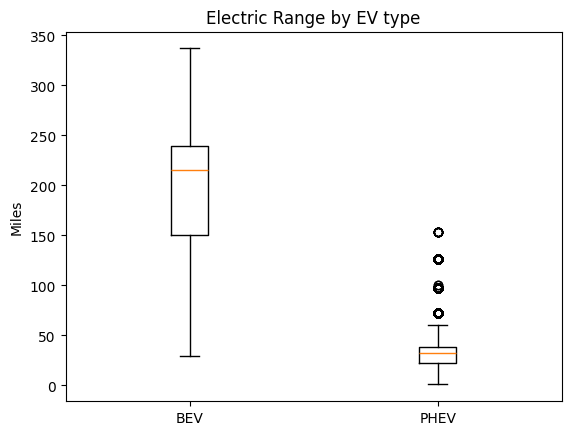

In [12]:
# Skewness, kurtosis, IQR outliers
for name, x in [("BEV", bev), ("PHEV", phev)]:
    q1, q2, q3 = x.quantile([0.25, 0.5, 0.75])
    pearson = 3 * (x.mean() - x.median()) / x.std()
    bowley = (q3 + q1 - 2 * q2) / (q3 - q1)
    kurt = ((x - x.mean()) ** 4).mean() / x.std() ** 4 - 3
    iqr = q3 - q1
    out = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
    print(name, " Pearson skew:", round(pearson, 3), " Bowley:", round(bowley, 3),
          " Excess kurtosis:", round(kurt, 3), " IQR outliers:", out)

plt.boxplot([bev, phev], labels=["BEV", "PHEV"])
plt.title("Electric Range by EV type")
plt.ylabel("Miles")
plt.show()

**Inference:** BEV SD is about 72 mi, PHEV SD about 14 mi, but PHEV varies more relative to its mean (CV 43% vs 36%).
BEV range is slightly left-skewed (many 200+ mi cars, a few old 70-90 mi ones). PHEV has a long right tail
(BMW i3, up to 153 mi), giving high kurtosis and about 1,291 IQR outliers. These are real cars, so we keep them.

## Phase 3: Visualization

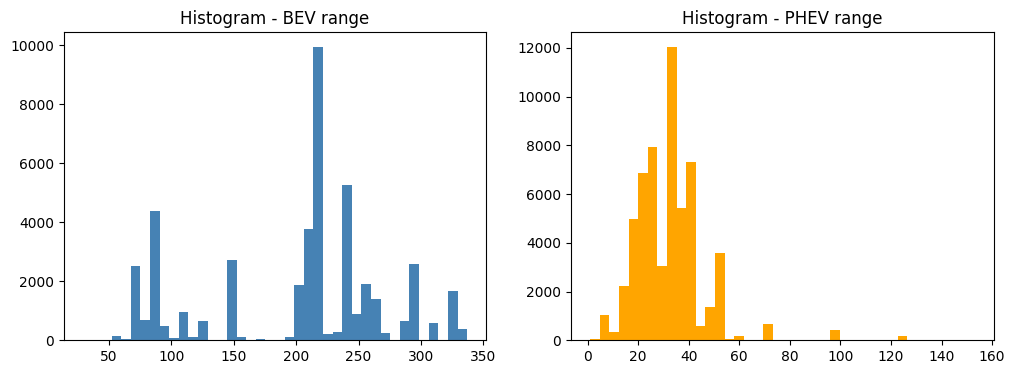

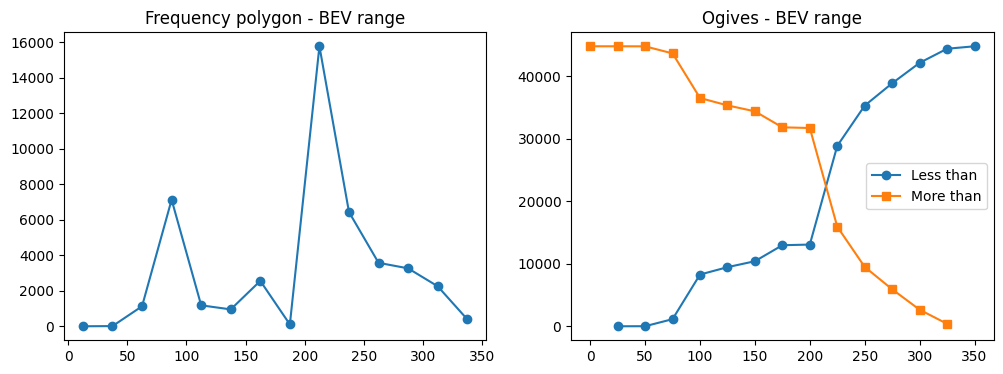

In [13]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.hist(bev, bins=40, color="steelblue")
plt.title("Histogram - BEV range")
plt.subplot(1, 2, 2)
plt.hist(phev, bins=40, color="orange")
plt.title("Histogram - PHEV range")
plt.show()

# Frequency polygon + ogive
f, e = np.histogram(bev, bins=np.arange(0, 375, 25))
mid = (e[:-1] + e[1:]) / 2
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(mid, f, marker="o")
plt.title("Frequency polygon - BEV range")
plt.subplot(1, 2, 2)
plt.plot(e[1:], np.cumsum(f), marker="o", label="Less than")
plt.plot(e[:-1], f.sum() - np.cumsum(f) + f, marker="s", label="More than")
plt.legend()
plt.title("Ogives - BEV range")
plt.show()

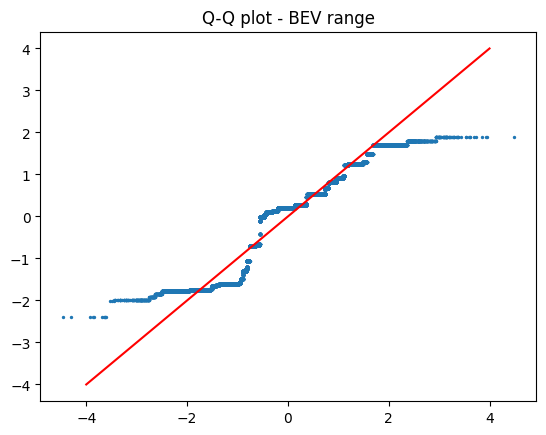

In [14]:
# Q-Q plot (compare with normal values generated by numpy)
np.random.seed(42)
z = (np.sort(bev.values) - bev.mean()) / bev.std()
normal = np.sort(np.random.normal(0, 1, len(z)))
plt.scatter(normal, z, s=2)
plt.plot([-4, 4], [-4, 4], color="red")
plt.title("Q-Q plot - BEV range")
plt.show()

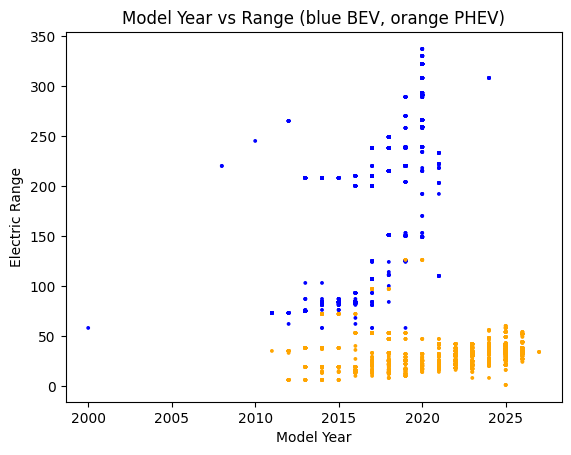

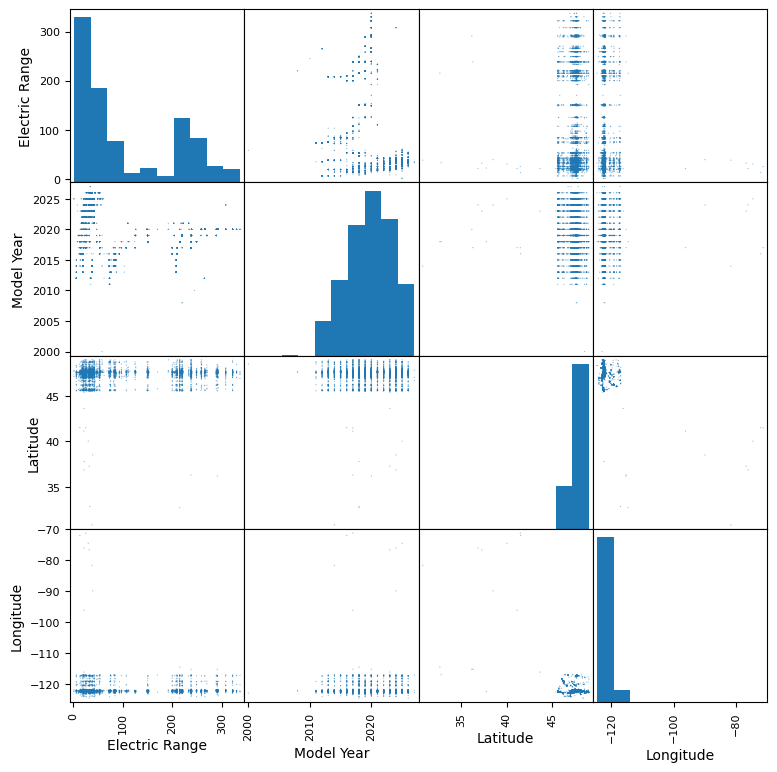

                Electric Range  Model Year  Latitude  Longitude
Electric Range           1.000      -0.290     0.015     -0.009
Model Year              -0.290       1.000     0.005     -0.004
Latitude                 0.015       0.005     1.000     -0.428
Longitude               -0.009      -0.004    -0.428      1.000
BEV only: 0.704


In [15]:
# Scatter plot and pair plot
s = df.dropna(subset=["Electric Range"]).sample(5000, random_state=42)
plt.scatter(s["Model Year"], s["Electric Range"], s=3, c=np.where(s["EV"] == "BEV", "blue", "orange"))
plt.xlabel("Model Year")
plt.ylabel("Electric Range")
plt.title("Model Year vs Range (blue BEV, orange PHEV)")
plt.show()

pd.plotting.scatter_matrix(s[["Electric Range", "Model Year", "Latitude", "Longitude"]], figsize=(9, 9), s=3)
plt.show()

print(df[["Electric Range", "Model Year", "Latitude", "Longitude"]].corr().round(3))
print("BEV only:", round(df[df["EV"] == "BEV"][["Electric Range", "Model Year"]].corr().iloc[0, 1], 3))

**Inference:** Histograms show separate peaks for each type. The ogives cross at the median (215 mi).
The Q-Q plot bends away from the red line, so range is not normal. Pooled correlation of range with model year
is negative (-0.29) but inside BEVs it is positive (about +0.7): mixing the two groups flips the sign.

===== SCOREBOARD =====
Total EVs: 300142
BEV share %: 80.6
Tesla share %: 40.7
King County share %: 48.0
Median BEV range: 215.0
Range not researched %: 65.7


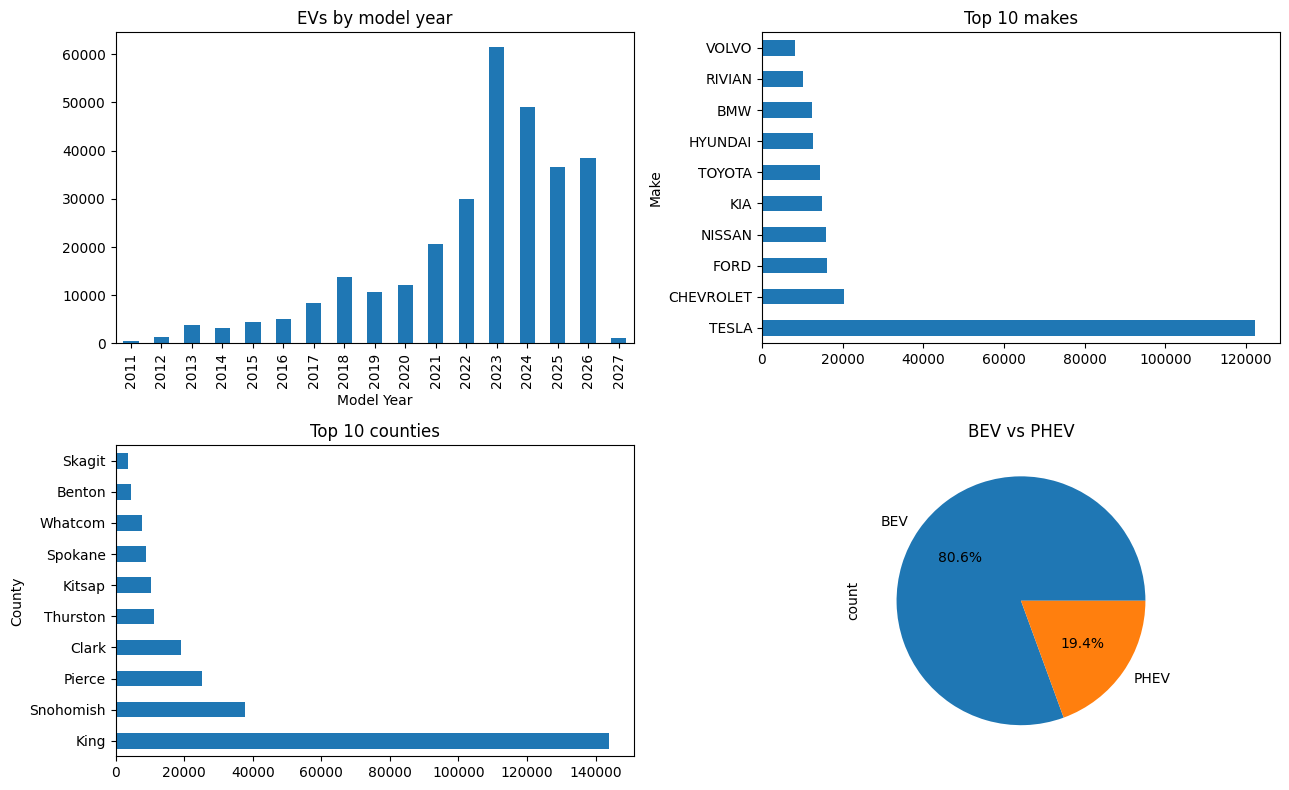

Spokane top makes:
 Make
TESLA        3088
CHEVROLET     648
FORD          609
KIA           509
TOYOTA        479
Name: count, dtype: int64


In [16]:
# Scoreboard + dashboard
print("===== SCOREBOARD =====")
print("Total EVs:", len(df))
print("BEV share %:", round((df["EV"] == "BEV").mean() * 100, 1))
print("Tesla share %:", round((df["Make"] == "TESLA").mean() * 100, 1))
print("King County share %:", round((df["County"] == "King").mean() * 100, 1))
print("Median BEV range:", bev.median())
print("Range not researched %:", round(df["Electric Range"].isnull().mean() * 100, 1))

fig, ax = plt.subplots(2, 2, figsize=(13, 8))
df["Model Year"].value_counts().sort_index().loc[2011:].plot(kind="bar", ax=ax[0, 0], title="EVs by model year")
df["Make"].value_counts().head(10).plot(kind="barh", ax=ax[0, 1], title="Top 10 makes")
df["County"].value_counts().head(10).plot(kind="barh", ax=ax[1, 0], title="Top 10 counties")
df["EV"].value_counts().plot(kind="pie", ax=ax[1, 1], autopct="%1.1f%%", title="BEV vs PHEV")
plt.tight_layout()
plt.show()

# Drill-down example: pick a county
county = "Spokane"
print(county, "top makes:\n", df[df["County"] == county]["Make"].value_counts().head(5))

## Phase 4: Interpretation & Storytelling
1. **Fast growth:** about 79% of EVs are model year 2021 or newer. Charging and grid demand are still rising fast.
2. **Concentration:** King County has 48% of EVs, and King + Snohomish + Pierce have 69%. Grid upgrades pay back first there.
3. **East vs West:** Eastern WA has only 8.6% of EVs and more PHEVs (24.5% vs 18.9%), likely due to long trips and fewer
   fast chargers. More highway chargers are needed there.
4. **Tesla leads with 40.7%,** but the number of brands per year grew from 12 (2015) to 35 (2026).
5. **Range improved a lot:** median BEV range went from 73 mi (2011) to 291 mi (2020).
6. **PHEVs pass 30 miles:** 92% of 2026 PHEVs are eligible vs 22% in 2020, so a higher threshold makes sense for future incentives.
7. **Data gap:** 65.7% of ranges are 0 (not researched). The DOL should fill them from EPA data.

**Recommendations:** treat 0 as missing, analyse BEV and PHEV separately, build chargers in Eastern WA,
plan grid upgrades in King/Snohomish/Pierce, and fix city-name typos in the source data.